In [228]:
import keras_ocr
from tensorflow import keras
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib import transforms
import cv2

from PIL import Image
import numpy as np
import random
import tensorflow_probability as tfp

In [2]:
import keras_cv

Using TensorFlow backend


C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
image_file = "Images/image_50402305.JPG"

In [4]:
tf_img = tf.io.read_file("Images/image_50402305.JPG")
tf_img = tf.image.decode_jpeg(tf_img, 1)

In [5]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read("Images/image_50402305.JPG")]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5

Instructions for updating:
Use `tf.image.resize(...method=ResizeMethod.BILINEAR...)` instead.

Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
8/8 [==============================] - 30s 3s/step


In [6]:
prediction_groups = prediction_groups[0]

---

In [95]:
# Define functions for dealing with images

image_width = 512 # 128
image_height = 128 # 32

def GetBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    # Each of these 4 variables is an edge of the box
    
    return x_max, x_min, y_max, y_min

def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

def DisplayWord(word):
    word = tf.reshape(word, (image_width, image_height, 1))
    
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)

    plt.imshow(word[:, :, 0], cmap='gray')
    plt.show()

def WordBox(Pred):
    x_max, x_min, y_max, y_min = GetBox(Pred)

    print("The word is identified as: ", Pred[0])

    print(int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word) # This returns a tensorflow image object

The word is identified as:  slepy
538 994 96 163


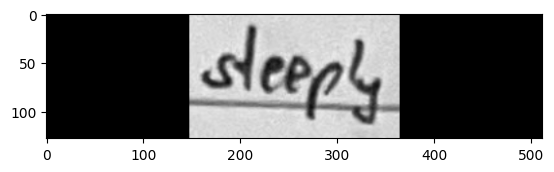

In [96]:
res = WordBox(prediction_groups[57])
DisplayWord(res)

In [97]:
word = res # This will be processed in the below code

# Pre-processing

In [98]:
from skimage.morphology import medial_axis, skeletonize, thin

from skimage.util import invert
import skimage

Make the image black background on white

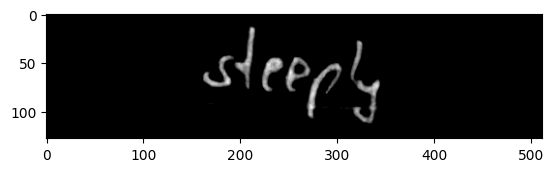

In [99]:
def BgChange(word, CleaningCoefficient):

    # The higher the CleaningCoefficient, the more of the dimmer features that are cleaned out

    image = [ [ 0 for i in range(len(word[i])) ]  for i in range(len(word))]

    for i in range(len(word)):
        for j in range(len(word[i])):
            # if word[i][j][0] > 0.6:
            #     tf.print(word[i][j][0])
            #     image[i][j] = [1]
            # else:
            #     image[i][j] = [0]

            temp = float(word[i][j][0]) * CleaningCoefficient

            if temp == 0:
                temp = 1

            if temp > 1:
                temp = 1

            image[i][j] = temp

    image = tf.constant(image)

    image = skimage.img_as_float(image)
    image = invert(image)

    DisplayWord(image)

    return image
    
image = BgChange(word, 3)

Remove Line (hasn't worked out as of yet)

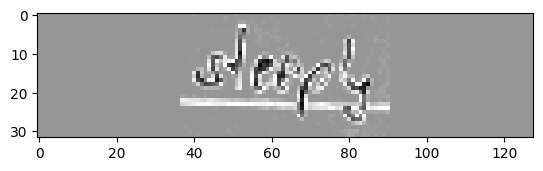

In [ ]:
A = BgChange(word, 1.5)
A = BgChange(word, 3)

C = A - 2 * B

DisplayWord(C)



In [101]:
line_thickness=2

img = res

# Apply binary thresholding to get a binary image
binary_image = tf.where(img < 0.5, 0.0, 1.0)

# Create a horizontal kernel
kernel = tf.ones((1, line_thickness, 1, 1), dtype=tf.float32)

# Apply 1D convolution to detect horizontal lines
lines_detected = tf.nn.conv2d(binary_image[None, ..., None], kernel, strides=[1, 1, 1, 1], padding='SAME')[0, ..., 0]

# Set pixels corresponding to detected lines to 0
result_image = tf.where(lines_detected > 0, 0.0, img)


Slope removal

In [107]:
def RotateImage(image, angle):
    image = tf.reshape(image, [image_width,image_height])
    im = image.numpy()
    im = Image.fromarray(im)
    im_rotated = im.rotate(angle=angle)
    im = np.asarray(im_rotated)
    image_r = tf.convert_to_tensor(im)

    return image_r

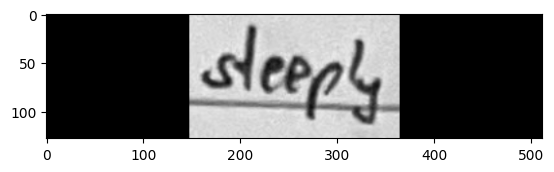

In [108]:
DisplayWord(word)

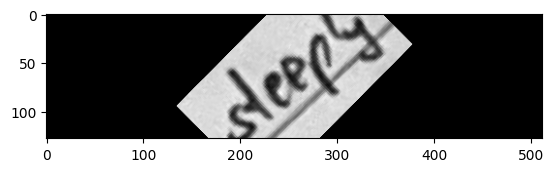

In [109]:
DisplayWord(RotateImage(word, 45))

In [112]:
def HorizontallHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    sums = tf.map_fn(lambda x: tf.math.reduce_sum(x), image)
    return sums

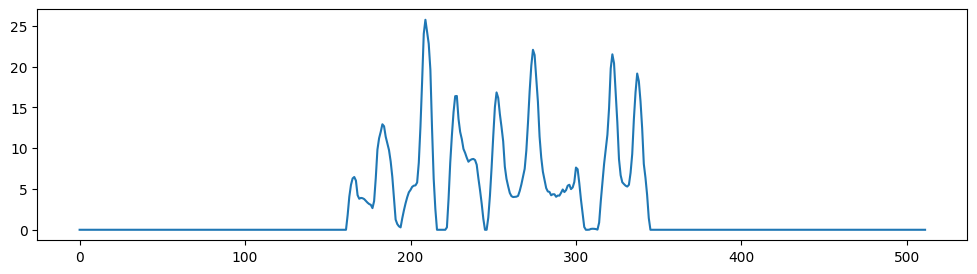

In [113]:
plt.figure(figsize=(12,3))
plt.plot(HorizontallHistorgram(image))

In [114]:
def VerticalHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    sums = tf.reduce_sum(image, axis=0)
    return sums

In [125]:
VerticalHistorgram(image)

<tf.Tensor: shape=(128,), dtype=float32, numpy=
array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        1.2178857 ,  3.2424445 ,  4.78631   ,  5.970506  ,  6.590406  ,
        6.964899  ,  7.2594905 ,  7.5680246 ,  8.107397  ,  7.905267  ,
        7.4832015 ,  7.573068  ,  8.15679   ,  8.537051  , 10.666573  ,
       12.523238  , 11.874908  ,  8.7521515 ,  7.798724  ,  7.310737  ,
        7.1008215 ,  6.1705155 ,  5.9827147 ,  5.9626684 ,  5.9818344 ,
        5.865113  ,  6.0157566 ,  6.404744  ,  7.002888  ,  7.988393  ,
        8.99568   , 10.516706  , 13.592318  , 18.42212   , 22.089706  ,
       24.73136   , 26.21503   , 29.244574  , 31.51427   , 34.06608   ,
       36.33801   , 34.985336  , 31.141476  , 27.95803   , 26.187582  ,
       25.433308  , 25.469797  , 26.78819   , 28.276896  , 27.621214  ,
       27.36716 

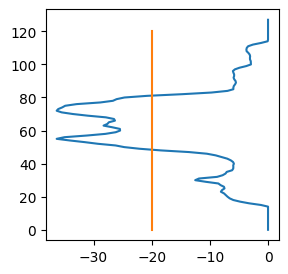

In [132]:
plt.figure(figsize=(3,3))
base = plt.gca().transData
rot = transforms.Affine2D().rotate_deg(90)

plt.plot(VerticalHistorgram(image), transform = rot + base)

plt.plot([-20, -20], [-0, 120])

In [220]:
def GetVariance(Vals, threshold):
    below_threshold_mask = tf.math.less_equal(Vals, threshold)
    weight_below = tf.math.reduce_sum(tf.cast(below_threshold_mask, dtype=tf.float32))
    vals_below = tf.cast(below_threshold_mask, dtype=tf.float32) * Vals # These are the values below the threshold
    vals_below = tf.boolean_mask(vals_below, tf.math.logical_not(tf.math.equal(vals_below, 0))) # Remove the zeros
    variance_below_threshold = tf.math.reduce_variance(vals_below)

    above_threshold_mask = tf.math.greater(Vals, threshold)
    weight_above = tf.math.reduce_sum(tf.cast(above_threshold_mask, dtype=tf.float32))
    vals_above = tf.cast(above_threshold_mask, dtype=tf.float32) * Vals # These are the values above the threshold
    vals_above = tf.boolean_mask(vals_above, tf.math.logical_not(tf.math.equal(vals_above, 0))) # Remove the zeros
    variance_above_threshold = tf.math.reduce_variance(vals_above)

    weighted_variance = ( variance_above_threshold * weight_above + variance_below_threshold * weight_below ) / ( weight_above + weight_below )

    return weighted_variance

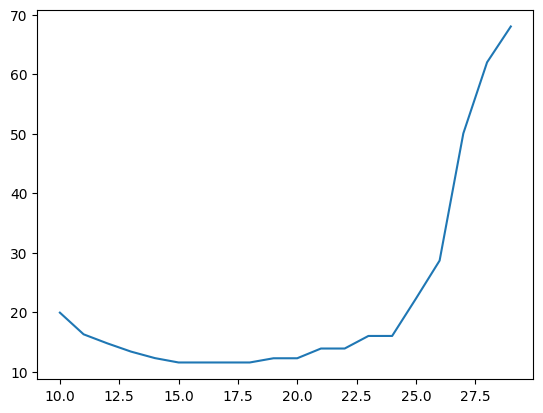

In [227]:
# Find the core region and the area of the image to be scanned

Vals = VerticalHistorgram(image)

x = []
y = []

for i in range(10, 30, 1):
    x.append(i)

    y.append(GetVariance(Vals, i))

plt.plot(x, y)

In [230]:
tfp.stats.percentile(Vals, 75)

<tf.Tensor: shape=(), dtype=float32, numpy=20.774166>

In [ ]:
        grads_and_vars = self.compute_gradients(loss, var_list, tape)
        self.apply_gradients(grads_and_vars)

<tf.Tensor: shape=(), dtype=float32, numpy=32.15884>

Slant removal

In [36]:
# Begin from the findings from the paper

Make the characters 1 pixel wide

In [37]:
skeleton = thin(image, max_num_iter=1)

# or skeletonize(image)

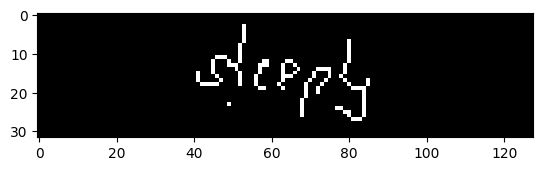

In [38]:
DisplayWord(skeleton)

In [39]:
skel, distance = medial_axis(image, return_distance=True)

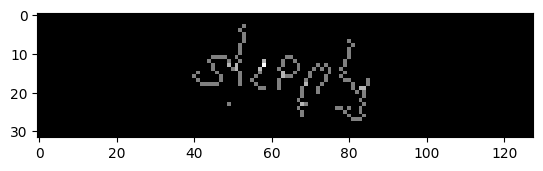

In [40]:
dist_on_skel = distance * skel
DisplayWord(dist_on_skel)

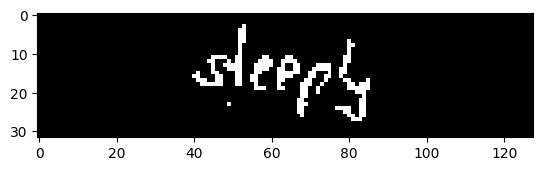

In [41]:
def convert_non_zero_to_one(tensor):
    # Create a boolean mask for non-zero values
    non_zero_mask = tf.math.not_equal(tensor, 0)
    
    # Convert non-zero values to 1 using the boolean mask
    result_tensor = tf.where(non_zero_mask, 1, tensor)
    
    return result_tensor

DisplayWord(convert_non_zero_to_one(image))